Step 1 — Download the Turtle GIS dataset

In [18]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aegoliusfunereus/china-testudines-gis-dataset-clean-and-curated")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/aegoliusfunereus/china-testudines-gis-dataset-clean-and-curated


Step 2 — Check the downloaded files

In [19]:
import os

print("Files available in the dataset:")

for file in os.listdir(path):
    print(file)

Files available in the dataset:
cleaned_data.csv
raw_data.tsv


Step 3 — Load the cleaned dataset

In [20]:
import pandas as pd
import os

csv_path = os.path.join(path, "cleaned_data.csv")

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (12494, 9)

Column names:
['ScientificName', 'Family', 'Genus', 'Province', 'Latitude', 'Longitude', 'Year', 'Province_CN', 'Family_CN']


,ScientificName,Family,Genus,Province,Latitude,Longitude,Year,Province_CN,Family_CN
0,"Chelonia mydas (Linnaeus, 1758)",Cheloniidae,Chelonia,Coastal Waters,22.355200,120.381000,2012.0,中国近海,海龟科
1,"Mauremys sinensis (Gray, 1834)",Geoemydidae,Mauremys,Taiwan,23.190018,120.306568,2026.0,中国台湾省,地龟科
2,"Mauremys reevesii (Gray, 1831)",Geoemydidae,Mauremys,Fujian,24.539079,118.299976,2025.0,福建省,地龟科
3,"Chelonia mydas (Linnaeus, 1758)",Cheloniidae,Chelonia,Taiwan,22.639518,121.508217,2026.0,中国台湾省,海龟科
4,"Mauremys reevesii (Gray, 1831)",Geoemydidae,Mauremys,Shanghai,31.304011,121.513219,2026.0,上海市,地龟科


Step 4 — Install libraries

In [21]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn folium joblib

Note: you may need to restart the kernel to use updated packages.


Step 5 — Load and validate the dataset

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import joblib

from folium.plugins import MarkerCluster
from IPython.display import display
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/turtleguard_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reload the CSV if df is not already available
if "df" not in globals():
    df = pd.read_csv(os.path.join(path, "cleaned_data.csv"))

df.columns = df.columns.str.strip()

required = ["ScientificName", "Family", "Latitude", "Longitude"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("Original dataset:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Original dataset: (12494, 9)
Columns: ['ScientificName', 'Family', 'Genus', 'Province', 'Latitude', 'Longitude', 'Year', 'Province_CN', 'Family_CN']


,ScientificName,Family,Genus,Province,Latitude,Longitude,Year,Province_CN,Family_CN
0,"Chelonia mydas (Linnaeus, 1758)",Cheloniidae,Chelonia,Coastal Waters,22.355200,120.381000,2012.0,中国近海,海龟科
1,"Mauremys sinensis (Gray, 1834)",Geoemydidae,Mauremys,Taiwan,23.190018,120.306568,2026.0,中国台湾省,地龟科
2,"Mauremys reevesii (Gray, 1831)",Geoemydidae,Mauremys,Fujian,24.539079,118.299976,2025.0,福建省,地龟科
3,"Chelonia mydas (Linnaeus, 1758)",Cheloniidae,Chelonia,Taiwan,22.639518,121.508217,2026.0,中国台湾省,海龟科
4,"Mauremys reevesii (Gray, 1831)",Geoemydidae,Mauremys,Shanghai,31.304011,121.513219,2026.0,上海市,地龟科


Step 6 — Clean the records

In [23]:
clean = df.copy()

for col in ["Latitude", "Longitude", "Year"]:
    if col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")

clean["ScientificName"] = clean["ScientificName"].astype("string").str.strip()
clean["Family"] = clean["Family"].astype("string").str.strip()

clean = clean.dropna(
    subset=["ScientificName", "Family", "Latitude", "Longitude"]
)

clean = clean[
    clean["Latitude"].between(-90, 90)
    & clean["Longitude"].between(-180, 180)
]

clean = clean[
    clean["ScientificName"].ne("")
    & clean["Family"].ne("")
]

clean = clean.drop_duplicates().reset_index(drop=True)

# Grid cells approximately 0.5 degrees wide for observation summaries
clean["lat_grid"] = np.floor(clean["Latitude"] * 2) / 2
clean["lon_grid"] = np.floor(clean["Longitude"] * 2) / 2
clean["grid_id"] = (
    clean["lat_grid"].astype(str) + "_" +
    clean["lon_grid"].astype(str)
)

clean.to_csv(OUTPUT_DIR / "cleaned_turtles.csv", index=False)

print("Cleaned dataset:", clean.shape)
print("Rows removed:", len(df) - len(clean))
print("Missing years:", clean["Year"].isna().sum())
display(clean.head())

Cleaned dataset: (8873, 12)
Rows removed: 3621
Missing years: 5


,ScientificName,Family,Genus,Province,Latitude,Longitude,Year,Province_CN,Family_CN,lat_grid,lon_grid,grid_id
0,"Chelonia mydas (Linnaeus, 1758)",Cheloniidae,Chelonia,Coastal Waters,22.355200,120.381000,2012.0,中国近海,海龟科,22.0,120.0,22.0_120.0
1,"Mauremys sinensis (Gray, 1834)",Geoemydidae,Mauremys,Taiwan,23.190018,120.306568,2026.0,中国台湾省,地龟科,23.0,120.0,23.0_120.0
2,"Mauremys reevesii (Gray, 1831)",Geoemydidae,Mauremys,Fujian,24.539079,118.299976,2025.0,福建省,地龟科,24.5,118.0,24.5_118.0
3,"Chelonia mydas (Linnaeus, 1758)",Cheloniidae,Chelonia,Taiwan,22.639518,121.508217,2026.0,中国台湾省,海龟科,22.5,121.5,22.5_121.5
4,"Mauremys reevesii (Gray, 1831)",Geoemydidae,Mauremys,Shanghai,31.304011,121.513219,2026.0,上海市,地龟科,31.0,121.5,31.0_121.5


Step 7 — Explore biodiversity records

7.1 Basic statistics


In [24]:
print("Unique recorded species:", clean["ScientificName"].nunique())
print("Recorded families:", clean["Family"].nunique())

if "Genus" in clean.columns:
    print("Recorded genera:", clean["Genus"].nunique())

print("\nTop families:")
display(clean["Family"].value_counts().head(15).to_frame("records"))

if "Province" in clean.columns:
    print("\nTop provinces:")
    
    display(clean["Province"].value_counts().head(15).to_frame("records"))

Unique recorded species: 43
Recorded families: 7
Recorded genera: 19

Top families:


,records
Family,
Geoemydidae,5465
Cheloniidae,2488
Trionychidae,772
Platysternidae,91
Emydidae,28
Dermochelyidae,20
Testudinidae,9



Top provinces:


,records
Province,
Taiwan,5619
Coastal Waters,2059
Hong Kong,360
Guangdong,212
Fujian,104
Beijing,77
Shanghai,61
Jiangsu,59
North,42


7.2 Plot the most frequently recorded species

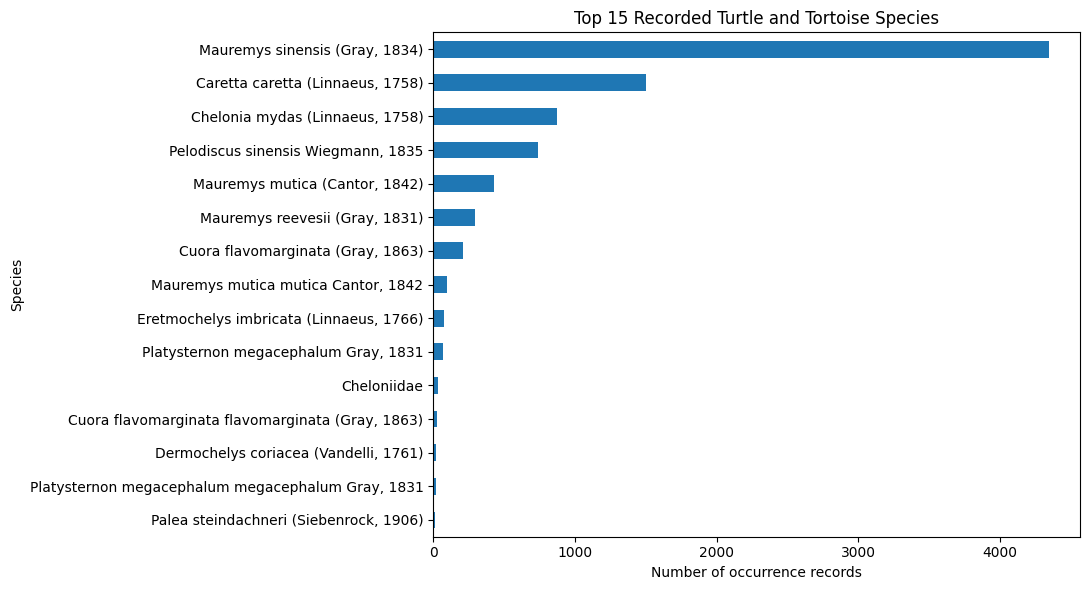

In [26]:
top_species = clean["ScientificName"].value_counts().head(15)

plt.figure(figsize=(11, 6))
top_species.sort_values().plot(kind="barh")
plt.title("Top 15 Recorded Turtle and Tortoise Species")
plt.xlabel("Number of occurrence records")
plt.ylabel("Species")
plt.tight_layout()
plt.show()

Step 8 — Create an interactive occurrence map

In [29]:
import folium
from folium.plugins import MarkerCluster
from IPython.display import display

map_df = clean.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Limit points to keep the map responsive
map_points = map_df.sample(
    n=min(3000, len(map_df)),
    random_state=42
)

center = [
    map_df["Latitude"].median(),
    map_df["Longitude"].median()
]

species_map = folium.Map(
    location=center,
    zoom_start=5,
    tiles="OpenStreetMap"
)

cluster = MarkerCluster().add_to(species_map)

for _, row in map_points.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=(
            f"Species: {row['ScientificName']}<br>"
            f"Family: {row['Family']}"
        ),
        tooltip=str(row["ScientificName"])
    ).add_to(cluster)

species_map.save(
    "/kaggle/working/species_occurrence_map.html"
)

display(species_map)

Step 9 — Identify observation hotspots

,lat_grid,lon_grid,record_count
198,25.0,121.5,1217
145,23.0,120.0,626
127,22.5,120.0,623
174,24.0,120.5,416
161,23.5,120.5,393
188,24.5,121.5,387
102,22.0,120.0,385
197,25.0,121.0,373
92,22.0,114.0,327
147,23.0,121.0,254


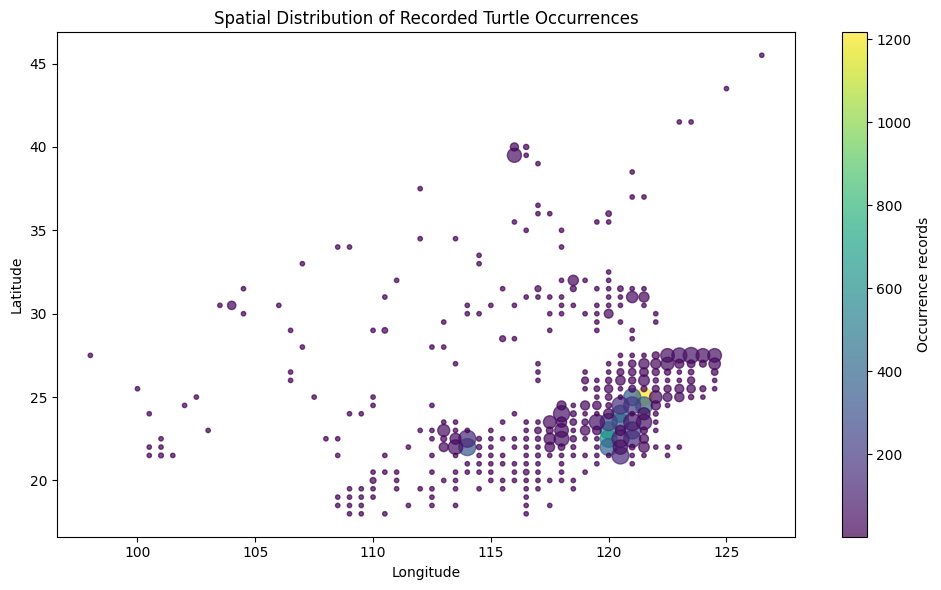

In [30]:
hotspots = (
    clean.groupby(["lat_grid", "lon_grid"])
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
)

hotspots.to_csv(OUTPUT_DIR / "observation_hotspots.csv", index=False)

display(hotspots.head(20))

plt.figure(figsize=(10, 6))
plt.scatter(
    hotspots["lon_grid"],
    hotspots["lat_grid"],
    c=hotspots["record_count"],
    s=np.clip(hotspots["record_count"] * 2, 10, 150),
    alpha=0.7
)
plt.colorbar(label="Occurrence records")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Recorded Turtle Occurrences")
plt.tight_layout()
plt.show()

In [32]:
import folium

# Create a map without external tiles or API keys
hotspot_map = folium.Map(
    location=center,
    zoom_start=5,
    tiles=None
)

# Add a plain background
folium.GeoJson(
    {
        "type": "FeatureCollection",
        "features": []
    },
    name="Observation hotspots"
).add_to(hotspot_map)

max_count = max(int(hotspots["record_count"].max()), 1)

for _, row in hotspots.iterrows():
    count = int(row["record_count"])

    folium.Circle(
        location=[
            row["lat_grid"] + 0.25,
            row["lon_grid"] + 0.25
        ],
        radius=3000 + 12000 * count / max_count,
        popup=(
            f"Grid: {row['lat_grid']}, {row['lon_grid']}<br>"
            f"Occurrence records: {count}"
        ),
        tooltip=f"{count} occurrence records",
        fill=True,
        fill_opacity=0.45
    ).add_to(hotspot_map)

# Save the interactive map
hotspot_map.save(
    str(OUTPUT_DIR / "observation_hotspot_map.html")
)

display(hotspot_map)

Step 10 — Train a machine-learning baseline

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

model_data = clean.dropna(
    subset=["Latitude", "Longitude", "Year", "Family"]
).copy()

model_data["Year"] = model_data["Year"].astype(int)

family_counts = model_data["Family"].value_counts()
valid_families = family_counts[family_counts >= 10].index

model_data = model_data[
    model_data["Family"].isin(valid_families)
].copy()

features = ["Latitude", "Longitude", "Year"]
target = "Family"

X = model_data[features]
y = model_data[target]

if y.nunique() < 2:
    raise ValueError(
        "At least two families with 10 or more dated records are needed."
    )

# Stratification requires at least two records per class
if y.value_counts().min() < 2:
    raise ValueError("Some families have too few records for stratified splitting.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
balanced_accuracy = balanced_accuracy_score(y_test, predictions)

print(f"Training records: {len(X_train):,}")
print(f"Test records: {len(X_test):,}")
print(f"Families modelled: {y.nunique()}")
print(f"Accuracy: {accuracy:.3f}")
print(f"Balanced accuracy: {balanced_accuracy:.3f}")

report = classification_report(
    y_test,
    predictions,
    zero_division=0
)

print("\nClassification report:\n")
print(report)

with open(OUTPUT_DIR / "model_metrics.txt", "w") as f:
    f.write(f"Accuracy: {accuracy:.4f}\n")
    f.write(f"Balanced accuracy: {balanced_accuracy:.4f}\n\n")
    f.write(report)

joblib.dump(
    {"model": model, "features": features, "target": target},
    OUTPUT_DIR / "family_classifier.joblib"
)

Training records: 7,087
Test records: 1,772
Families modelled: 6
Accuracy: 0.840
Balanced accuracy: 0.509

Classification report:

                precision    recall  f1-score   support

   Cheloniidae       0.97      0.97      0.97       497
Dermochelyidae       1.00      0.75      0.86         4
      Emydidae       0.00      0.00      0.00         6
   Geoemydidae       0.88      0.87      0.87      1093
Platysternidae       0.07      0.11      0.09        18
  Trionychidae       0.33      0.36      0.34       154

      accuracy                           0.84      1772
     macro avg       0.54      0.51      0.52      1772
  weighted avg       0.85      0.84      0.84      1772



['/kaggle/working/turtleguard_outputs/family_classifier.joblib']

Step 11 — Inspect model errors

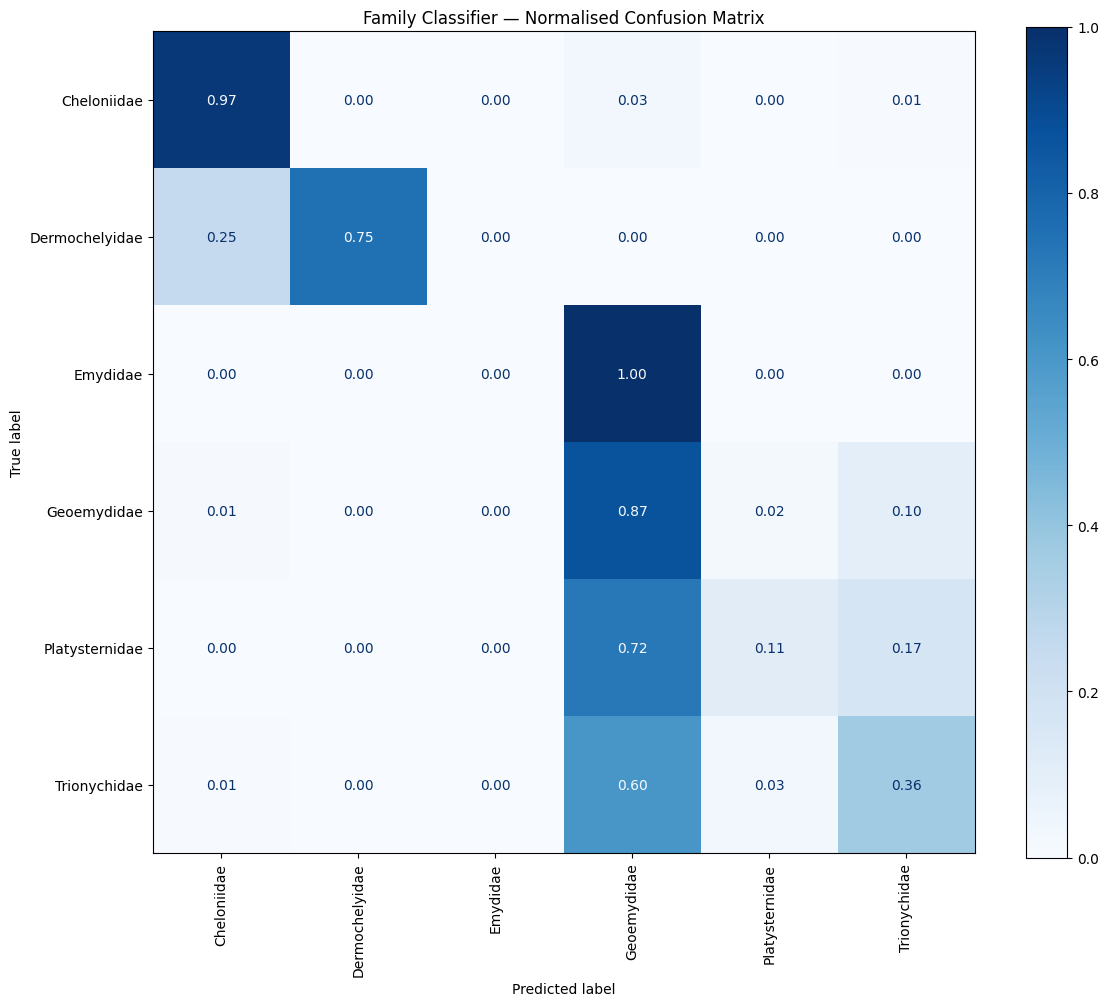

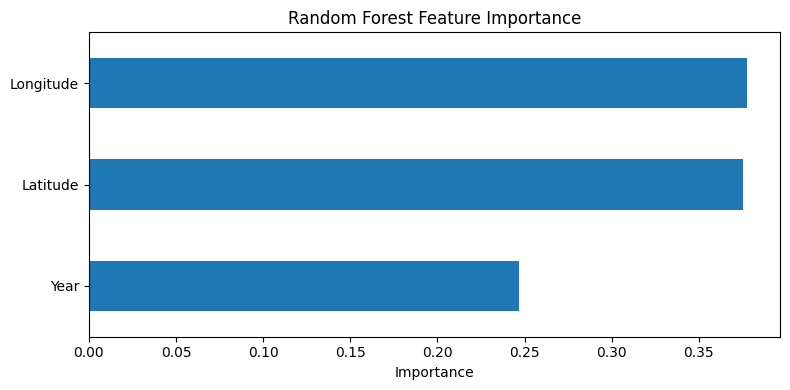

,importance
Longitude,0.377720
Latitude,0.375227
Year,0.247053


In [34]:
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    xticks_rotation=90,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax
)

ax.set_title("Family Classifier — Normalised Confusion Matrix")
plt.tight_layout()
plt.show()

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("importance"))

Step 12 — Summarise records by province and year

,occurrence_records,unique_species,unique_families
Province,,,
Taiwan,5619,19,5
Coastal Waters,2059,7,2
Hong Kong,360,19,5
Guangdong,212,11,5
Fujian,104,8,4
Beijing,77,4,2
Shanghai,61,4,2
Jiangsu,59,5,3
North,42,9,4


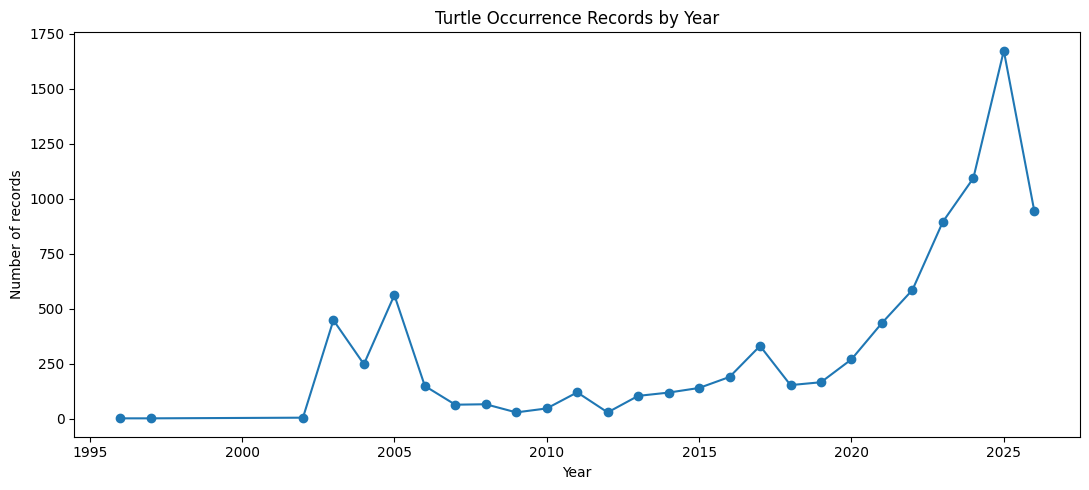

In [35]:
if "Province" in clean.columns:
    province_summary = (
        clean.groupby("Province")
        .agg(
            occurrence_records=("ScientificName", "size"),
            unique_species=("ScientificName", "nunique"),
            unique_families=("Family", "nunique")
        )
        .sort_values("occurrence_records", ascending=False)
    )

    province_summary.to_csv(OUTPUT_DIR / "province_summary.csv")
    display(province_summary.head(20))

if "Year" in clean.columns:
    yearly_summary = (
        clean.dropna(subset=["Year"])
        .groupby("Year")
        .agg(
            occurrence_records=("ScientificName", "size"),
            unique_species=("ScientificName", "nunique")
        )
        .reset_index()
        .sort_values("Year")
    )

    yearly_summary.to_csv(OUTPUT_DIR / "yearly_summary.csv", index=False)

    plt.figure(figsize=(11, 5))
    plt.plot(
        yearly_summary["Year"],
        yearly_summary["occurrence_records"],
        marker="o"
    )
    plt.title("Turtle Occurrence Records by Year")
    plt.xlabel("Year")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

Step 13 — Export all outputs

In [37]:
import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/TurtleGuard_GIS",
    "zip",
    root_dir=str(OUTPUT_DIR)
)

print("Export package:", zip_path)

Export package: /kaggle/working/TurtleGuard_GIS.zip
